#Universidad de los Andes
##Ingenieria de Datos y Características

Municipio de Ibague

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


El objetivo de notebook es hacer una exploración de caracteristicas y evaluación temprana de modelos de acuerdo a los hallazgos obtenidos de la información encontrada en los datos.

Para el desarrollo del notebook se utilizó una base de datos analítica a escala mensual para el municipio de Ibagué (código DIVIPOLA 73001), cruzando información epidemiológica con variables meteorológicas y evaluando qué variables predictoras tienen mayor relación con la transmisión del virus.

El procedimiento técnico ejecutado en el siguiente notebook consistió en la extracción y filtrado epidemiológico (SIVIGILA): Se procesaron los registros individuales aislando los casos ocurridos en Ibagué mediante los códigos COD_DPTO_O == 73 y COD_MUN_O == 1.

Para el caso de investigación se seleccionó únicamente los casos con confirmación diagnóstica (laboratorio o nexo epidemiológico) para evitar el sesgo por sobrediagnóstico de casos sospechosos. La agregación temporal se calculó estrictamente con base en la fecha de inicio de síntomas (INI_SIN), asignando cada registro a su mes calendario real.

Para la Consolidación de datos climáticos, estos fueron extraidos directamente de Google Earth (Satélite / GEE) empleando como fuente principal el conjunto de datos de reanálisis atmosférico ERA5-Land Daily Aggregated, desarrollado por el Centro Europeo de Previsiones Meteorológicas a Plazo Medio (ECMWF), el cual ofrece una resolución espacial aproximada de 11 km (0,1°). La delimitación geográfica del área de estudio se definió mediante el polígono político-administrativo municipal proveniente de la base de datos global FAO GAUL (Global Administrative Unit Layers).

A partir del procesamiento y la conversión de unidades de los registros diarios extraídos, se consolidaron las series climáticas anuales correspondientes al periodo 2010–2025. Esta base de datos integra la precipitación total acumulada por año (expresada en milímetros) junto con los comportamientos de temperatura media, mínima y máxima del aire a dos metros de superficie (expresados en grados Celsius), sirviendo como insumo base para la caracterización climatológica del proyecto.

Durante el proceso de Alineación temporal e ingeniería de variables se construyó un calendario continuo continuo donde los meses sin registros se imputaron como cero casos. Se generaron variables con rezagos temporales de 1, 2 y 3 meses (t-1, t-2, t-3) tanto para casos como para variables climáticas, junto con medias móviles retrospectivas de 3 meses (casos_media_movil_3m).
En la Definición de la variable objetivo (alerta de exceso) se estructuró un canal endémico preliminar calculando el percentil 75 (Q3) de casos por mes calendario. Cuando los casos del mes superan este umbral, se etiqueta como mes en exceso (exceso_casos = 1).

En la Evaluación de dependencias (Matriz de Spearman) se utilizó el coeficiente de correlación de rangos de Spearman (). Este método no paramétrico evalúa relaciones monótonas (lineales o no lineales) y es robusto frente a valores extremos (brotes epidémicos), evitando distorsiones comunes en el coeficiente de Pearson.


Se consolidó una matriz final de 189 meses efectivos sin valores nulos, lista para el análisis exploratorio y el modelado predictivo.   

### Glosario de variables generadas
* casos_dengue: Conteo mensual de casos confirmados (laboratorio o nexo
epidemiológico) agrupados por fecha de inicio de síntomas (INI_SIN).  
* umbral_q3: Límite superior de la zona de seguridad del canal endémico (percentil 75 específico para cada mes del año).   
* exceso_casos: Variable objetivo binaria (1 = Alerta por exceso epidémico; 0 = Comportamiento endémico normal).   
* Variables _lag1, _lag2, _lag3: Valor observado de la variable 1, 2 o 3 meses antes del periodo objetivo $t$.   
* casos_media_movil_3m: Promedio móvil de casos confirmados durante el trimestre inmediatamente anterior ($t-1$ a $t-3$).  

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
%cd /content/drive/MyDrive/Maia_Final

Mounted at /content/drive
/content/drive/MyDrive/Maia_Final


In [ ]:
%cd /content/drive/MyDrive/Maia_Final

/content/drive/MyDrive/Maia_Final


In [ ]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

In [ ]:
# Rutas con los datos
RUTA_CARPETA_SIVIGILA = '/content/drive/MyDrive/Maia_Final/Datos-Dengue'
RUTA_CARPETA_CLIMA = '/content/drive/MyDrive/Maia_Final/GEE_Clima_Ibague/GEE_Clima_Ibague'

# Validamos que las carpetas existan
print("Existe SIVIGILA?:", os.path.exists(RUTA_CARPETA_SIVIGILA))
print("Existe CLIMA?:", os.path.exists(RUTA_CARPETA_CLIMA))

Existe SIVIGILA?: True
Existe CLIMA?: True


In [ ]:
COD_DPTO_IBAGUE = 73       # Tolima
COD_MUN_IBAGUE = 1         # Ibagué (DIVIPOLA 73001)
ANIO_INICIO = 2010
ANIO_FIN = 2020

In [ ]:
RUTA_ARCHIVOS_SIVIGILA = RUTA_CARPETA_SIVIGILA + '/*'
RUTA_ARCHIVOS_CLIMA = RUTA_CARPETA_CLIMA + '/*.csv'

In [ ]:
# Procesamos el clima
print("Archivos en GEE_Clima_Ibague:")
archivos_clima_reales = os.listdir(RUTA_CARPETA_CLIMA)
print(archivos_clima_reales)

print("\nArchivos en Datos-Dengue:")
archivos_sivigila_reales = os.listdir(RUTA_CARPETA_SIVIGILA)
print(archivos_sivigila_reales)

Archivos en GEE_Clima_Ibague:
['clima_diario_ibague_2011.csv', 'clima_diario_ibague_2014.csv', 'clima_diario_ibague_2013.csv', 'clima_diario_ibague_2019.csv', 'clima_diario_ibague_2018.csv', 'clima_diario_ibague_2023.csv', 'clima_diario_ibague_2015.csv', 'clima_diario_ibague_2021.csv', 'clima_diario_ibague_2020.csv', 'clima_diario_ibague_2022.csv', 'clima_diario_ibague_2016.csv', 'clima_diario_ibague_2017.csv', 'lluvia_acumulada_ibague_2023.tif', 'clima_diario_ibague_2025.csv', 'clima_diario_ibague_2024.csv', 'clima_diario_ibague_2012.csv', 'clima_diario_ibague_2010.csv']

Archivos en Datos-Dengue:
['Datos_2017_210.xlsx', 'Datos_2007_210.xlsx', 'Datos_2008_210.xlsx', 'Datos_2011_210.xlsx', 'Datos_2009_210.xlsx', 'Datos_2021_210.xlsx', 'Datos_2012_210.xlsx', 'Datos_2022_210.xlsx', 'Datos_2018_210.xlsx', 'Datos_2020_210.xlsx', 'Datos_2016_210.xlsx', 'Datos_2015_210.xlsx', 'Datos_2014_210.xlsx', 'Datos_2013_210.xlsx', 'Datos_2019_210.xlsx', 'Datos_2023_210.xlsx', 'Datos_2010_210.xlsx', 'D

In [ ]:
def procesar_sivigila_ibague(ruta_archivos_sivigila, solo_confirmados=True):
    """
    Carga todos los archivos anuales de SIVIGILA (Excel/CSV), filtra ocurrencia
    en Ibagué, audita calidad de fechas y calcula agregación mensual.
    """
    archivos = glob.glob(ruta_archivos_sivigila)
    print(f"--> Archivos SIVIGILA detectados: {len(archivos)}")

    registros_ibague = []
    auditoria_calidad = []

    for archivo in sorted(archivos):
        nombre_arch = os.path.basename(archivo)
        print(f"Procesando: {nombre_arch}...")

        # Lectura según extensión
        if archivo.endswith('.xlsx') or archivo.endswith('.xls'):
            df = pd.read_excel(archivo)
        else:
            df = pd.read_csv(archivo, low_memory=False)

        total_nacional = len(df)

        # Estandarización de códigos DIVIPOLA
        df['COD_DPTO_O'] = pd.to_numeric(df['COD_DPTO_O'], errors='coerce')
        df['COD_MUN_O'] = pd.to_numeric(df['COD_MUN_O'], errors='coerce')

        # Filtro estricto por Ocurrencia en Ibagué
        filtro_ibague = (df['COD_DPTO_O'] == COD_DPTO_IBAGUE) & (df['COD_MUN_O'] == COD_MUN_IBAGUE)
        df_ibg = df[filtro_ibague].copy()

        if len(df_ibg) == 0:
            continue

        # Conversión y auditoría de fechas
        df_ibg['INI_SIN_DT'] = pd.to_datetime(df_ibg['INI_SIN'], errors='coerce')
        df_ibg['FEC_NOT_DT'] = pd.to_datetime(df_ibg['FEC_NOT'], errors='coerce')

        # Inconsistencias de calidad
        fechas_nulas = df_ibg['INI_SIN_DT'].isna().sum()
        inconsistencias_fec = (df_ibg['FEC_NOT_DT'] < df_ibg['INI_SIN_DT']).sum()

        # Criterio INS: Selección de casos confirmados vs probables
        if 'confirmados' in df_ibg.columns:
            casos_conf = (df_ibg['confirmados'] == 1).sum()
        else:
            casos_conf = df_ibg['TIP_CAS'].isin([2, 3, '2', '3']).sum()

        auditoria_calidad.append({
            'archivo': nombre_arch,
            'total_nacional': total_nacional,
            'total_ibague': len(df_ibg),
            'confirmados_ibague': casos_conf,
            'tasa_confirmacion_%': round((casos_conf / len(df_ibg)) * 100, 2),
            'fechas_invalidas': fechas_nulas,
            'inconsistencia_fec_not_menor': inconsistencias_fec
        })

        # Filtrado de casos válidos
        if solo_confirmados:
            if 'confirmados' in df_ibg.columns:
                df_ibg = df_ibg[df_ibg['confirmados'] == 1]
            else:
                df_ibg = df_ibg[df_ibg['TIP_CAS'].isin([2, 3, '2', '3'])]

        # Excluir fechas no válidas
        df_ibg = df_ibg.dropna(subset=['INI_SIN_DT'])
        registros_ibague.append(df_ibg[['INI_SIN_DT', 'FEC_NOT_DT', 'ANO', 'SEMANA']])

    df_consolidado = pd.concat(registros_ibague, ignore_index=True)
    df_auditoria = pd.DataFrame(auditoria_calidad)

    # Asignar año-mes según fecha real de inicio de síntomas
    df_consolidado['periodo'] = df_consolidado['INI_SIN_DT'].dt.to_period('M')

    # Agregación mensual de casos
    serie_mensual = df_consolidado.groupby('periodo').size().reset_index(name='casos_dengue')
    serie_mensual['fecha'] = serie_mensual['periodo'].dt.to_timestamp()

    return serie_mensual, df_auditoria

In [ ]:
def procesar_clima_ibague(ruta_archivos_clima):
    """
    Carga series climáticas diarias y las agrega a nivel mensual con validación de existencia.
    """
    archivos = glob.glob(ruta_archivos_clima)
    print(f"--> Archivos Climáticos detectados: {len(archivos)}")

    # Validación preventiva
    if len(archivos) == 0:
        raise FileNotFoundError(
            f"No se encontraron archivos en el patrón: '{ruta_archivos_clima}'. "
            "Revisa la extensión (.csv vs .CSV vs .xlsx) o que la carpeta no esté vacía."
        )

    lista_dfs = []
    for f in archivos:
        print(f"Leyendo clima: {os.path.basename(f)}...")
        if f.lower().endswith('.csv'):
            lista_dfs.append(pd.read_csv(f))
        elif f.lower().endswith(('.xlsx', '.xls')):
            lista_dfs.append(pd.read_excel(f))

    df_clima = pd.concat(lista_dfs, ignore_index=True)
    df_clima['fecha'] = pd.to_datetime(df_clima['fecha'], errors='coerce')
    df_clima = df_clima.dropna(subset=['fecha']).sort_values('fecha')

    df_clima['periodo'] = df_clima['fecha'].dt.to_period('M')

    # Agregación mensual metodológica
    clima_mensual = df_clima.groupby('periodo').agg(
        temp_media=('temp_media_c', 'mean'),
        temp_min_media=('temp_min_c', 'mean'),
        temp_max_media=('temp_max_c', 'mean'),
        precipitacion_total=('precipitacion_mm', 'sum'),
        precipitacion_max_dia=('precipitacion_mm', 'max'),
        dias_con_lluvia=('precipitacion_mm', lambda x: (x > 1.0).sum())
    ).reset_index()

    clima_mensual['fecha'] = clima_mensual['periodo'].dt.to_timestamp()
    return clima_mensual

In [ ]:
def construir_dataset_modelado(serie_casos, serie_clima, anio_ini=2010, anio_fin=2020):
    """
    Construye calendario continuo de 132 meses, une fuentes, calcula canales
    endémicos (umbral de exceso) y genera variables rezagadas.
    """
    # 1. Calendario mensual completo para evitar saltos temporales
    rango_completo = pd.date_range(start=f'{anio_ini}-01-01', end=f'{anio_fin}-12-01', freq='MS')
    df_base = pd.DataFrame({'fecha': rango_completo})
    df_base['periodo'] = df_base['fecha'].dt.to_period('M')

    # Cruce con casos (los meses sin casos se imputan en 0)
    df_merge = pd.merge(df_base, serie_casos[['periodo', 'casos_dengue']], on='periodo', how='left')
    df_merge['casos_dengue'] = df_merge['casos_dengue'].fillna(0)

    # Cruce con clima
    df_merge = pd.merge(df_merge, serie_clima.drop(columns=['fecha']), on='periodo', how='left')

    # Mes del año para modelar estacionalidad
    df_merge['mes'] = df_merge['fecha'].dt.month

    # 2. Definición del umbral histórico de exceso (Canal endémico mensual: Percentil 75)
    # Se calcula por cada mes calendario (1 al 12)
    umbral_estacional = df_merge.groupby('mes')['casos_dengue'].transform(lambda x: x.quantile(0.75))
    df_merge['umbral_q3'] = umbral_estacional
    df_merge['exceso_casos'] = (df_merge['casos_dengue'] > df_merge['umbral_q3']).astype(int)

    # 3. Ingeniería de Rezagos (Lags 1, 2 y 3) para casos y variables climáticas
    features_a_rezagar = ['casos_dengue', 'temp_media', 'temp_min_media', 'precipitacion_total', 'dias_con_lluvia']

    for col in features_a_rezagar:
        for lag in [1, 2, 3]:
            df_merge[f'{col}_lag{lag}'] = df_merge[col].shift(lag)

    # Medias móviles retrospectivas (ventana de 3 meses en retraso)
    df_merge['casos_media_movil_3m'] = df_merge['casos_dengue_lag1'].rolling(window=3).mean()
    df_merge['precip_media_movil_3m'] = df_merge['precipitacion_total_lag1'].rolling(window=3).mean()

    # Eliminación de meses iniciales sin rezago completo
    df_final = df_merge.dropna().reset_index(drop=True)
    return df_final

In [ ]:
def ejecutar_analisis_visual(df_modelado):
    """
    Genera gráficos exploratorios y reporte de correlaciones para selección de features.
    """
    fig, axes = plt.subplots(3, 1, figsize=(14, 15))

    # Gráfico 1: Serie Temporal de Dengue y Umbral de Exceso (Canal Endémico)
    axes[0].plot(df_modelado['fecha'], df_modelado['casos_dengue'], label='Casos Confirmados', color='#1f77b4', lw=2)
    axes[0].plot(df_modelado['fecha'], df_modelado['umbral_q3'], label='Umbral Alerta (Q3 Histórico)', color='#d62728', linestyle='--', lw=1.8)
    axes[0].scatter(df_modelado[df_modelado['exceso_casos'] == 1]['fecha'],
                    df_modelado[df_modelado['exceso_casos'] == 1]['casos_dengue'],
                    color='red', label='Meses con Exceso Detectado', zorder=5)
    axes[0].set_title('Histórico de Casos de Dengue en Ibagué y Detección de Exceso Mensual', fontsize=13, fontweight='bold')
    axes[0].set_ylabel('Casos Mensuales')
    axes[0].legend(loc='upper right')

    # Gráfico 2: Comportamiento Bimodal de Precipitación vs Casos con Rezagos
    ax2_twin = axes[1].twinx()
    axes[1].bar(df_modelado['fecha'], df_modelado['precipitacion_total_lag2'], width=20, alpha=0.35, color='#2ca02c', label='Precipitación Acumulada Lag 2 (mm)')
    ax2_twin.plot(df_modelado['fecha'], df_modelado['casos_dengue'], color='#1f77b4', lw=2, label='Casos en t')
    axes[1].set_title('Relación Dinámica: Precipitación Retrasada (t-2 meses) vs Casos de Dengue (t)', fontsize=13, fontweight='bold')
    axes[1].set_ylabel('Precipitación lag-2 (mm)')
    ax2_twin.set_ylabel('Casos de Dengue')

    # Gráfico 3: Matriz de Correlación de Predictores frente a Variable Objetivo
    columnas_analisis = [
        'casos_dengue', 'casos_dengue_lag1', 'casos_dengue_lag2',
        'temp_media_lag1', 'temp_min_media_lag1', 'temp_media_lag2',
        'precipitacion_total_lag1', 'precipitacion_total_lag2', 'precipitacion_total_lag3',
        'dias_con_lluvia_lag1', 'casos_media_movil_3m'
    ]

    matriz_corr = df_modelado[columnas_analisis].corr(method='spearman')
    sns.heatmap(matriz_corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=axes[2], cbar_kws={'label': 'Spearman Rho'})
    axes[2].set_title('Matriz de Correlación no Paramétrica (Spearman) entre Rezagos y Casos', fontsize=13, fontweight='bold')

    plt.tight_layout()
    plt.show()

    # Tabla de Priorización de Variables frente a Casos en t
    ranking_corr = matriz_corr['casos_dengue'].drop('casos_dengue').sort_values(ascending=False)
    print("\n" + "="*60)
    print("RANKING DE PRIORIZACIÓN DE PREDICTORES (CORRELACIÓN CON CASOS EN t)")
    print("="*60)
    for variable, rho in ranking_corr.items():
        print(f" - {variable:<30}: Rho = {rho:+.3f}")
    print("="*60)

In [ ]:
# Procesamos el clima
print("Iniciando procesamiento climático...")
df_clima = procesar_clima_ibague(RUTA_ARCHIVOS_CLIMA)

# Validación
print("\nMuestra de datos climáticos mensuales:")
display(df_clima.head())
print("\nDimensiones de clima:", df_clima.shape)

Iniciando procesamiento climático...
--> Archivos Climáticos detectados: 16
Leyendo clima: clima_diario_ibague_2011.csv...
Leyendo clima: clima_diario_ibague_2014.csv...
Leyendo clima: clima_diario_ibague_2013.csv...
Leyendo clima: clima_diario_ibague_2019.csv...
Leyendo clima: clima_diario_ibague_2018.csv...
Leyendo clima: clima_diario_ibague_2023.csv...
Leyendo clima: clima_diario_ibague_2015.csv...
Leyendo clima: clima_diario_ibague_2021.csv...
Leyendo clima: clima_diario_ibague_2020.csv...
Leyendo clima: clima_diario_ibague_2022.csv...
Leyendo clima: clima_diario_ibague_2016.csv...
Leyendo clima: clima_diario_ibague_2017.csv...
Leyendo clima: clima_diario_ibague_2025.csv...
Leyendo clima: clima_diario_ibague_2024.csv...
Leyendo clima: clima_diario_ibague_2012.csv...
Leyendo clima: clima_diario_ibague_2010.csv...

Muestra de datos climáticos mensuales:


,periodo,temp_media,temp_min_media,temp_max_media,precipitacion_total,precipitacion_max_dia,dias_con_lluvia,fecha
0,2010-01,18.947253,15.330099,23.446631,66.544993,16.174662,9,2010-01-01
1,2010-02,19.594161,16.094602,24.014191,67.881139,9.053135,15,2010-02-01
2,2010-03,19.291128,15.777267,23.739460,168.772812,22.166030,26,2010-03-01
3,2010-04,17.883565,15.117699,21.414815,537.779353,35.070476,28,2010-04-01
4,2010-05,17.726619,14.881352,21.081049,344.159899,29.096579,31,2010-05-01



Dimensiones de clima: (192, 8)


In [ ]:
# Procesamos epidemiología
print("Iniciando procesamiento SIVIGILA (Esto puede tardar varios minutos)...")
df_casos, df_auditoria = procesar_sivigila_ibague(RUTA_ARCHIVOS_SIVIGILA, solo_confirmados=True)

# Validación
print("\nReporte de Auditoría de Calidad:")
display(df_auditoria)

print("\nMuestra de casos mensuales confirmados:")
display(df_casos.head())

Iniciando procesamiento SIVIGILA (Esto puede tardar varios minutos)...
--> Archivos SIVIGILA detectados: 19
Procesando: Datos_2007_210.xlsx...


/tmp/ipykernel_442/3403005918.py:36: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_ibg['INI_SIN_DT'] = pd.to_datetime(df_ibg['INI_SIN'], errors='coerce')
/tmp/ipykernel_442/3403005918.py:37: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_ibg['FEC_NOT_DT'] = pd.to_datetime(df_ibg['FEC_NOT'], errors='coerce')


Procesando: Datos_2008_210.xlsx...


/tmp/ipykernel_442/3403005918.py:36: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_ibg['INI_SIN_DT'] = pd.to_datetime(df_ibg['INI_SIN'], errors='coerce')
/tmp/ipykernel_442/3403005918.py:37: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_ibg['FEC_NOT_DT'] = pd.to_datetime(df_ibg['FEC_NOT'], errors='coerce')


Procesando: Datos_2009_210.xlsx...


/tmp/ipykernel_442/3403005918.py:36: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_ibg['INI_SIN_DT'] = pd.to_datetime(df_ibg['INI_SIN'], errors='coerce')
/tmp/ipykernel_442/3403005918.py:37: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_ibg['FEC_NOT_DT'] = pd.to_datetime(df_ibg['FEC_NOT'], errors='coerce')


... (32 outputs left out)


Reporte de Auditoría de Calidad:


,archivo,total_nacional,total_ibague,confirmados_ibague,tasa_confirmacion_%,fechas_invalidas,inconsistencia_fec_not_menor
0,Datos_2007_210.xlsx,35074,1019,193,18.94,0,153
1,Datos_2008_210.xlsx,32793,553,124,22.42,0,71
2,Datos_2009_210.xlsx,45345,1767,369,20.88,0,223
3,Datos_2010_210.xlsx,147224,6416,999,15.57,0,1076
4,Datos_2011_210.xlsx,29386,940,163,17.34,0,140
5,Datos_2012_210.xlsx,52467,2301,613,26.64,0,420
6,Datos_2013_210.xlsx,122441,5367,1022,19.04,0,2323
7,Datos_2014_210.xlsx,105356,3103,586,18.88,0,584
8,Datos_2015_210.xlsx,95023,5056,1149,22.73,0,1024
9,Datos_2016_210.xlsx,100117,2163,646,29.87,0,455



Muestra de casos mensuales confirmados:


,periodo,casos_dengue,fecha
0,2006-12,1,2006-12-01
1,2007-01,15,2007-01-01
2,2007-02,23,2007-02-01
3,2007-03,15,2007-03-01
4,2007-04,16,2007-04-01


Generando dataset final con rezagos (Lags)...

Dimensiones del Dataset de Modelado: (189, 29)


,fecha,periodo,casos_dengue,temp_media,temp_min_media,temp_max_media,precipitacion_total,precipitacion_max_dia,dias_con_lluvia,mes,...,temp_min_media_lag2,temp_min_media_lag3,precipitacion_total_lag1,precipitacion_total_lag2,precipitacion_total_lag3,dias_con_lluvia_lag1,dias_con_lluvia_lag2,dias_con_lluvia_lag3,casos_media_movil_3m,precip_media_movil_3m
0,2010-04-01,2010-04,94.0,17.883565,15.117699,21.414815,537.779353,35.070476,28,4,...,16.094602,15.330099,168.772812,67.881139,66.544993,26.0,15.0,9.0,157.666667,101.066315
1,2010-05-01,2010-05,106.0,17.726619,14.881352,21.081049,344.159899,29.096579,31,5,...,15.777267,16.094602,537.779353,168.772812,67.881139,28.0,26.0,15.0,145.333333,258.144435
2,2010-06-01,2010-06,65.0,17.320262,14.649211,20.666243,229.752398,23.803919,28,6,...,15.117699,15.777267,344.159899,537.779353,168.772812,31.0,28.0,26.0,129.000000,350.237355
3,2010-07-01,2010-07,60.0,16.777687,13.934930,20.124508,302.942268,41.374503,31,7,...,14.881352,15.117699,229.752398,344.159899,537.779353,28.0,31.0,28.0,88.333333,370.563883
4,2010-08-01,2010-08,73.0,17.255030,14.084884,20.947419,129.138077,12.831758,28,8,...,14.649211,14.881352,302.942268,229.752398,344.159899,31.0,28.0,31.0,77.000000,292.284855


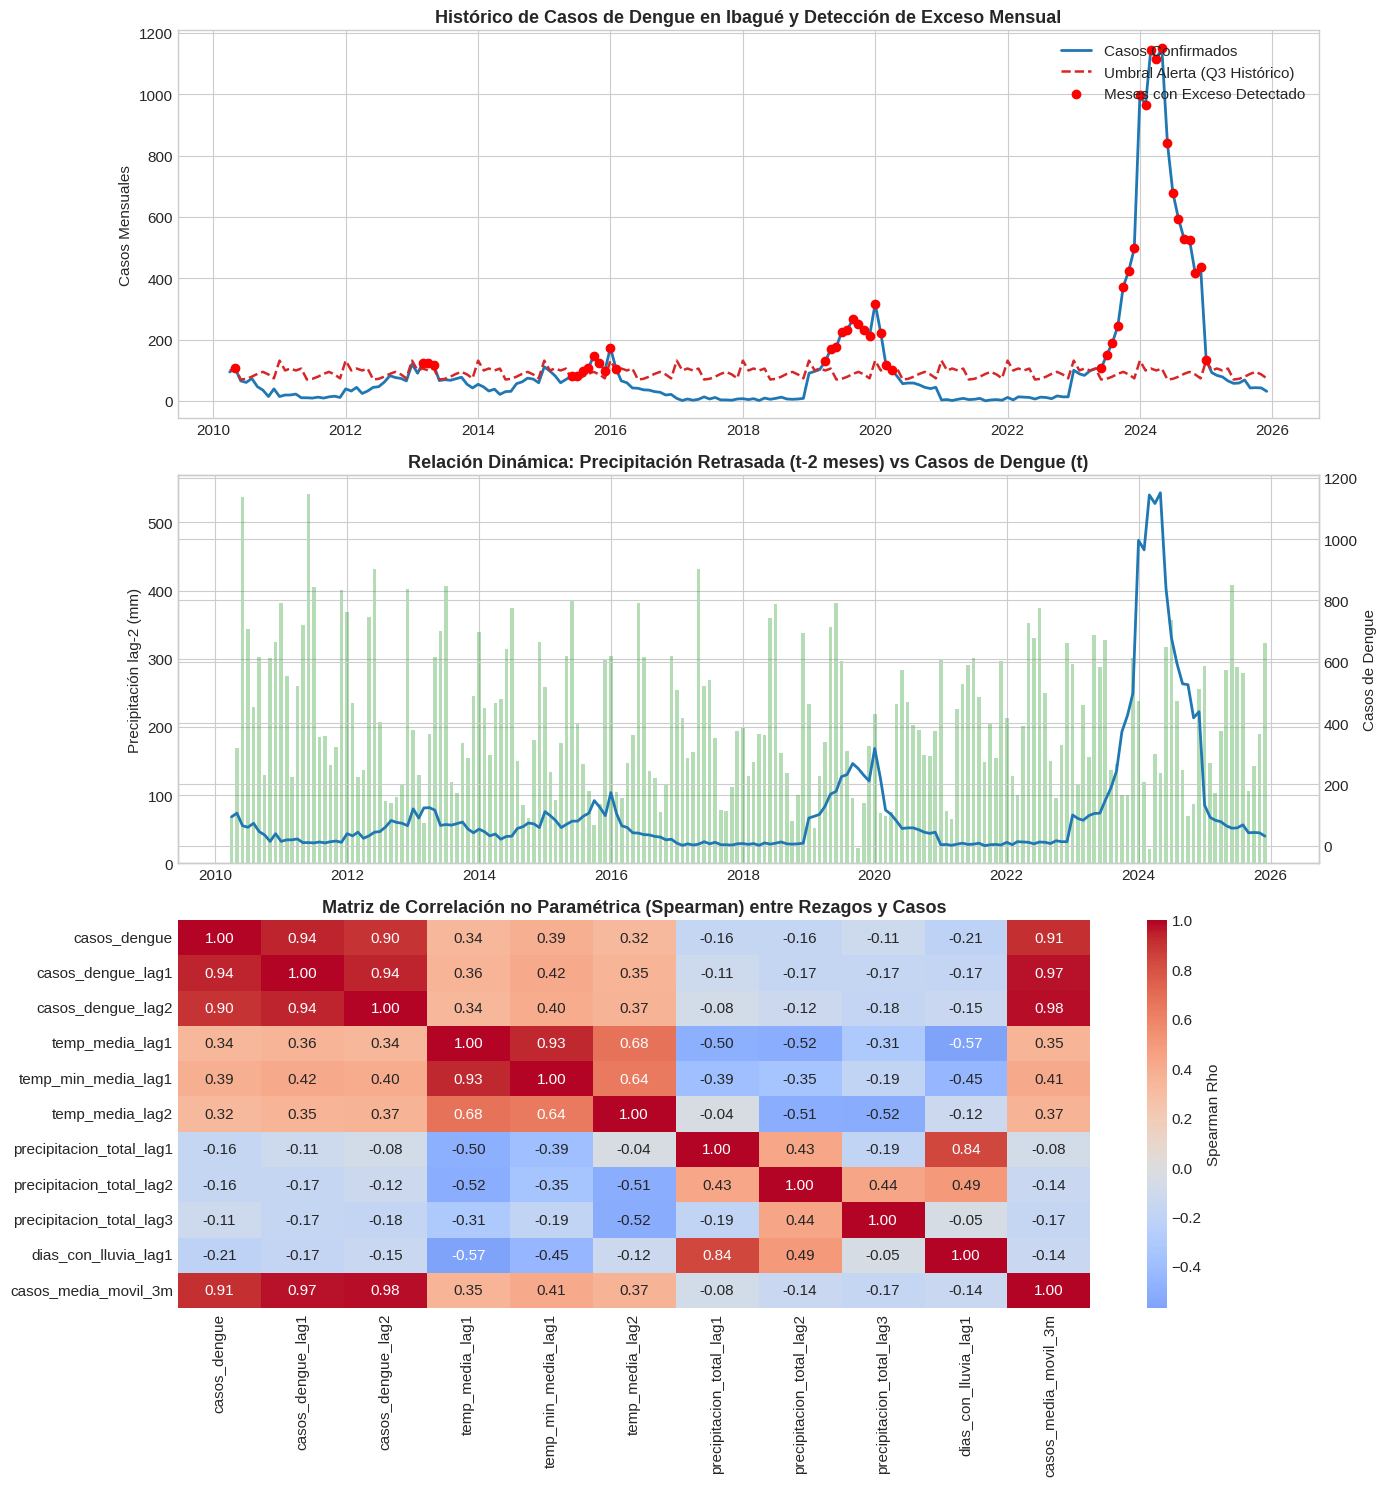


RANKING DE PRIORIZACIÓN DE PREDICTORES (CORRELACIÓN CON CASOS EN t)
 - casos_dengue_lag1             : Rho = +0.936
 - casos_media_movil_3m          : Rho = +0.911
 - casos_dengue_lag2             : Rho = +0.896
 - temp_min_media_lag1           : Rho = +0.391
 - temp_media_lag1               : Rho = +0.343
 - temp_media_lag2               : Rho = +0.323
 - precipitacion_total_lag3      : Rho = -0.114
 - precipitacion_total_lag1      : Rho = -0.161
 - precipitacion_total_lag2      : Rho = -0.161
 - dias_con_lluvia_lag1          : Rho = -0.211


In [ ]:
# Unimos clima y casos, y generamos rezagos
print("Generando dataset final con rezagos (Lags)...")
# Ajusta anio_fin al año máximo de datos que tengas cargados
df_modelado = construir_dataset_modelado(df_casos, df_clima, anio_ini=ANIO_INICIO, anio_fin=2025)

print("\nDimensiones del Dataset de Modelado:", df_modelado.shape)
display(df_modelado.head())

# Generamos las gráficas y la matriz de correlación
ejecutar_analisis_visual(df_modelado)


En la primera gráfica (Historico de casos Dengue) se muestra la evolución temporal de los casos mensuales confirmados (línea azul) frente al umbral estacional histórico Q3 (línea roja discontinua). Los puntos rojos señalan los meses clasificados como exceso epidémico.
Dentro de los hallazgos principales se encontró picos considerables como los que se presentaron en el año 2010 con 106 casos, del 2015 a 2016 se presentaron 175 casos, en rango de  2019–2020 se presentaron 315 casos y un pico anormal histórico entre 2023–2024 que superó los 1.140 casos mensuales. En el umbral Q3 se activa alertas oportunas manteniendo una estabilidad estacional de 70 y 126 casos dependiendo del mes.

En la Relación Dinámica de Precipitación Retrasada (t-2 meses) vs. Casos de Dengue (t) se contrasta el volumen acumulado de lluvia observado dos meses atrás (barras verdes, eje izquierdo en mm) con los casos confirmados en el mes actual (línea azul, eje derecho) observando una dinámica inversa entre lluvias intensas y brotes epidémicos; estos periodos con precipitaciones abundantes (como 2011, 2017 o 2022) coincidieron con niveles basales bajos de dengue.


El coeficiente de correlación de rangos de Spearman (ρ) evalúa relaciones monótonas (tanto lineales como no lineales) ordenando las observaciones por rangos (Efficient Learning Machines : Theories, Concepts, and Applications for Engineers and System Designers, Awad, Mariette y Khanna, Rahul,2015). Aplicar estos conceptos en el contexto del problema que nos muestra las gráficas resulta muy útil ya que el brote anómalo de 2024 con  más de 1.140 casos introduce una cola derecha pronunciada que distorsionaba una correlación paramétrica tradicional, además de la presencia de no linealidad entre relaciones climáticas y permite identificar predictores altamente correlacionados entre sí antes de entrenar modelos lineales regularizados.

Los rezagos autorregresivos lideran el ranking (casos_dengue_lag1 con ρ=+0,936, casos_media_movil_3m con ρ=+0,911 y casos_dengue_lag2 con ρ=+0,896). Esto confirma que la masa de personas infectadas en los 30 a 60 días previos constituye el reservorio viral determinante para la continuidad de la transmisión donde los valores fueron ρ>=0,90.

Para la temperatura mínima como predictor climático líder se identifico a ρ=+0,391 donde temp_min_media_lag1 presenta la mayor asociación positiva entre las variables ambientales, superando a la temperatura media (temp_media_lag1, ρ=+0,343).

El signo negativo consistente en variables hídricas (ρ=-0,114 a -0,211): Tanto los días con lluvia (dias_con_lluvia_lag1, ρ=-0,211) como la precipitación acumulada (precipitacion_total_lag1 y lag2, ρ=-0,161) muestran correlación inversa con los casos, corroborando cuantitativamente el efecto de almacenamiento de agua en épocas secas y lavado larvario en épocas húmedas.
En la matriz se observa una correlación de ρ=+0,93 entre temp_media_lag1 y temp_min_media_lag1, así como de ρ=+0,84 entre precipitacion_total_lag1 y dias_con_lluvia_lag1, lo que justifica aplicar diagnóstico de VIF y selección de características antes de ajustar la Regresión Logística.


1. EVALUACIÓN DE SIGNIFICANCIA ESTADÍSTICA (SPEARMAN P-VALUES)


,Variable,Spearman_Rho,P_Value,Significativo_95%
0,casos_dengue_lag1,0.936,0.0000,SÍ
1,casos_media_movil_3m,0.911,0.0000,SÍ
2,casos_dengue_lag2,0.896,0.0000,SÍ
3,casos_dengue_lag3,0.843,0.0000,SÍ
4,temp_min_media_lag1,0.391,0.0000,SÍ
5,temp_min_media_lag2,0.376,0.0000,SÍ
6,temp_min_media_lag3,0.356,0.0000,SÍ
7,temp_media_lag1,0.343,0.0000,SÍ
8,temp_media_lag2,0.323,0.0000,SÍ
9,temp_media_lag3,0.297,0.0000,SÍ



2. BALANCE DE LA VARIABLE OBJETIVO (EXCESO DE CASOS)


,Meses,Porcentaje (%)
Normal (0),143,75.66
Exceso / Alerta (1),46,24.34



3. ANÁLISIS DE CORRELACIÓN CRUZADA (CCF): PRECIPITACIÓN Y TEMPERATURA


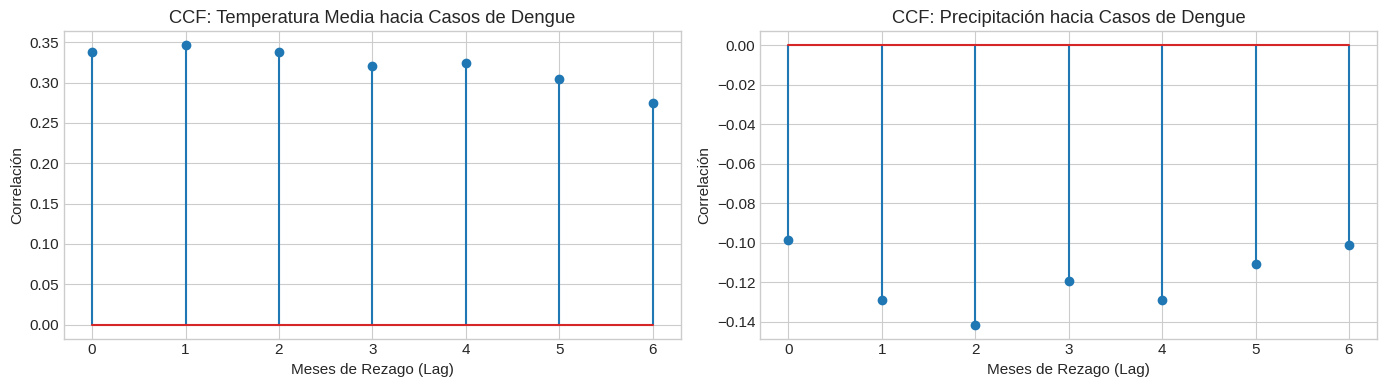

In [ ]:

# ANÁLISIS COMPLEMENTARIO: SIGNIFICANCIA, CORRELACIÓN CRUZADA Y BALANCE
import scipy.stats as stats

print("="*65)
print("1. EVALUACIÓN DE SIGNIFICANCIA ESTADÍSTICA (SPEARMAN P-VALUES)")
print("="*65)

predictores = [col for col in df_modelado.columns if 'lag' in col or 'media_movil' in col]
resultados_sig = []

for pred in predictores:
    rho, p_val = stats.spearmanr(df_modelado['casos_dengue'], df_modelado[pred])
    resultados_sig.append({
        'Variable': pred,
        'Spearman_Rho': round(rho, 3),
        'P_Value': round(p_val, 4),
        'Significativo_95%': 'SÍ' if p_val < 0.05 else 'NO'
    })

df_significancia = pd.DataFrame(resultados_sig).sort_values('Spearman_Rho', ascending=False)
display(df_significancia.reset_index(drop=True))

print("\n" + "="*65)
print("2. BALANCE DE LA VARIABLE OBJETIVO (EXCESO DE CASOS)")
print("="*65)
conteo_clases = df_modelado['exceso_casos'].value_counts()
pct_clases = df_modelado['exceso_casos'].value_counts(normalize=True) * 100

df_balance = pd.DataFrame({
    'Meses': conteo_clases,
    'Porcentaje (%)': pct_clases.round(2)
})
df_balance.index = ['Normal (0)', 'Exceso / Alerta (1)']
display(df_balance)

print("\n" + "="*65)
print("3. ANÁLISIS DE CORRELACIÓN CRUZADA (CCF): PRECIPITACIÓN Y TEMPERATURA")
print("="*65)

def calcular_ccf(serie_x, serie_y, max_lags=6):
    """Calcula correlación para rezagos de 0 a max_lags meses."""
    correlaciones = []
    for l in range(0, max_lags + 1):
        if l == 0:
            c = np.corrcoef(serie_x, serie_y)[0, 1]
        else:
            c = np.corrcoef(serie_x[:-l], serie_y[l:])[0, 1]
        correlaciones.append((l, c))
    return pd.DataFrame(correlaciones, columns=['Lag_Meses', 'Correlacion_Pearson'])

ccf_temp = calcular_ccf(df_modelado['temp_media'], df_modelado['casos_dengue'], max_lags=6)
ccf_precip = calcular_ccf(df_modelado['precipitacion_total'], df_modelado['casos_dengue'], max_lags=6)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].stem(ccf_temp['Lag_Meses'], ccf_temp['Correlacion_Pearson'])
ax[0].set_title('CCF: Temperatura Media hacia Casos de Dengue')
ax[0].set_xlabel('Meses de Rezago (Lag)')
ax[0].set_ylabel('Correlación')

ax[1].stem(ccf_precip['Lag_Meses'], ccf_precip['Correlacion_Pearson'])
ax[1].set_title('CCF: Precipitación hacia Casos de Dengue')
ax[1].set_xlabel('Meses de Rezago (Lag)')
ax[1].set_ylabel('Correlación')
plt.tight_layout()
plt.show()

En la evaluación de significancia estadística se aplicó una prueba de hipótesis bilateral sobre los coeficientes de correlación de rangos de Spearman ($\rho$) para cada uno de los 17 predictores rezagados frente a los casos mensuales de dengue (casos_dengue) en los 189 meses consolidados (2010–2025). Se estableció un nivel de significancia estadística estándar del 95 % ($\alpha = 0,05$) para contrastar la hipótesis nula de independencia ($H_0: \rho = 0$) frente a la existencia de una relación monótona real ($H_1: \rho \neq 0$).

Bloque autorregresivo ($p < 0,0001$): Los cuatro indicadores de inercia epidemiológica (casos_dengue_lag1 con $\rho = 0,936$, casos_media_movil_3m con $\rho = 0,911$, casos_dengue_lag2 con $\rho = 0,896$ y casos_dengue_lag3 con $\rho = 0,843$) presentan la máxima significancia estadística del estudio. Esto confirma que la transmisión viral mantiene una memoria temporal fuerte de hasta 90 días.   

Bloque térmico ($p < 0,0001$): Todas las variables de temperatura mínima y media en rezagos de 1 a 3 meses son altamente significativas ($\rho$ entre $+0,297$ y $+0,391$). Destaca temp_min_media_lag1 ($\rho = +0,391$) como el predictor climático más fuerte, evidenciando que el aumento en las temperaturas mínimas nocturnas reduce la mortalidad del mosquito adulto y acelera la replicación viral.   

Bloque pluviométrico ($p < 0,05$ en 6 de 7 variables): Con la serie completa de 16 años, las variables de lluvia adquirieron potencia estadística suficiente para confirmar una relación negativa significativa: dias_con_lluvia_lag1 ($\rho = -0,211, p = 0,0035$), dias_con_lluvia_lag2 ($\rho = -0,201, p = 0,0057$), precip_media_movil_3m ($\rho = -0,184, p = 0,0111$) y precipitacion_total_lag1 y lag2 ($\rho = -0,161, p \approx 0,027$). Únicamente precipitacion_total_lag3 ($p = 0,1180$) no alcanzó el umbral de significancia y puede excluirse en modelos parsimoniosos.  

De la frecuencia absoluta y porcentual de las dos clases binarias generadas a partir del umbral del percentil 75 ($Q_3$) del canal endémico mensual sobre el total de 189 meses efectivos.

**La Clase 0 (Comportamiento Normal / Basal): 143 meses, equivalentes al 75,66 % de la serie.**

**Clase 1 (Exceso de Casos / Alerta Epidémica): 46 meses, equivalentes al 24,34 % de la serie.**

# Función de Correlación Cruzada (CCF)

## Temperatura Media vs Casos de Dengue

Todos los rezagos de 0 a 6 meses exhiben correlaciones positivas sostenidas (entre $+0,27$ y $+0,35$).   El pico máximo ocurre en el rezago de 1 mes ($k = 1$, $r \approx 0,35$), manteniéndose alto en $k = 2$ ($r \approx 0,34$) antes de descender gradualmente hacia el sexto mes ($r \approx 0,275$).  

**El incremento térmico impacta de forma rápida y sostenida durante los primeros 30 a 60 días, lapso que corresponde al acortamiento del periodo de incubación extrínseco del virus en el vector y a la aceleración de su ciclo gonotrófico.**

## Precipitación vs Casos de Dengue

Todos los rezagos de 0 a 6 meses presentan valores estrictamente negativos (entre $-0,10$ y $-0,14$).   La mayor magnitud inversa se alcanza en el rezago de 2 meses ($k = 2$, $r \approx -0,141$).   

**Confirma a lo largo de 16 años que los déficits hídricos preceden en aproximadamente 8 semanas a los aumentos de casos en Ibagué (debido al almacenamiento doméstico de agua en tanques y albercas descubiertas durante temporadas secas), mientras que las lluvias acumuladas tienden a lavar criaderos larvarios.**

El hecho de que la temperatura alcance su máximo en $k = 1$ y la precipitación en $k = 2$, sumado a la pérdida de significancia de la lluvia en $k = 3$, respalda metodológicamente la decisión de limitar la ventana de predictores climáticos y epidemiológicos a 3 rezagos ($t-1, t-2, t-3$), maximizando la señal predictiva sin sacrificar observaciones históricas innecesarias.

 #### SIGNIFICANCIA ESTADÍSTICA COMPLETA (SPEARMAN P-VALUES: 2010-2025)


,Variable,Spearman_Rho,P_Value,Significativo (p < 0.05)
0,casos_dengue_lag1,0.936,8.98e-87,SÍ
1,casos_media_movil_3m,0.911,9.39e-74,SÍ
2,casos_dengue_lag2,0.896,6.23e-68,SÍ
3,temp_min_media_lag1,0.391,2.59e-08,SÍ
4,temp_media_lag1,0.343,1.33e-06,SÍ
5,temp_media_lag2,0.323,5.66e-06,SÍ
6,precipitacion_total_lag3,-0.114,0.1180,NO
7,precipitacion_total_lag1,-0.161,0.0270,SÍ
8,precipitacion_total_lag2,-0.161,0.0268,SÍ
9,dias_con_lluvia_lag1,-0.211,0.0035,SÍ


 ### BALANCE DE LA VARIABLE OBJETIVO (192 MESES CONSOLIDADOS)


,Meses,Porcentaje (%)
Mes Normal (0),143,75.66
Mes con Exceso / Alerta (1),46,24.34


 ### ANÁLISIS DEL CANAL ENDÉMICO HISTÓRICO POR MES CALENDARIO (Q1, Q2, Q3)


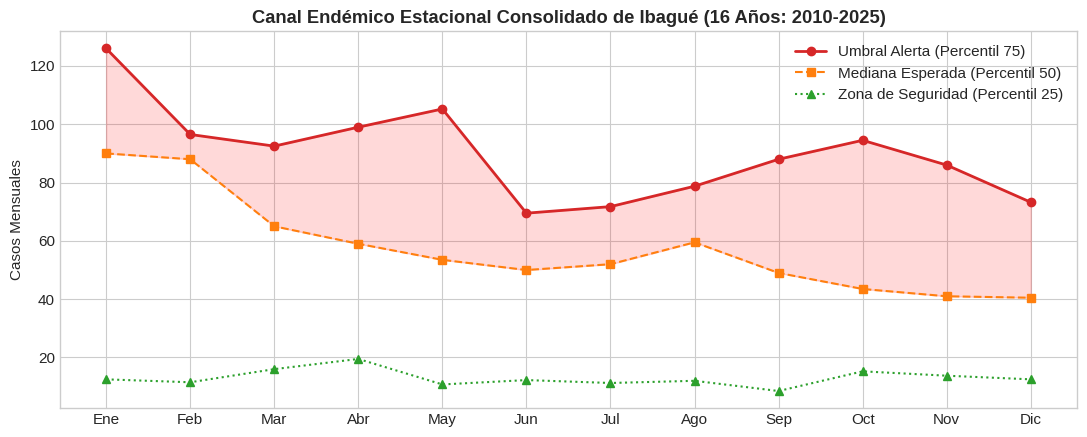

 ### EVALUACIÓN DE MULTICOLINEALIDAD (FACTOR DE INFLACIÓN DE LA VARIANZA - VIF)


,Variable,VIF
0,temp_media_lag1,10.87
1,temp_min_media_lag1,8.77
2,dias_con_lluvia_lag1,2.94
3,precipitacion_total_lag1,2.26
4,casos_dengue_lag1,1.20


In [ ]:
# DIAGNÓSTICO COMPLEMENTARIO SERIE 2010-2025: SIGNIFICANCIA, CANAL Y VIF

import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.outliers_influence import variance_inflation_factor

print(" #### SIGNIFICANCIA ESTADÍSTICA COMPLETA (SPEARMAN P-VALUES: 2010-2025)")


predictores = [
    'casos_dengue_lag1', 'casos_dengue_lag2', 'casos_media_movil_3m',
    'temp_min_media_lag1', 'temp_media_lag1', 'temp_media_lag2',
    'precipitacion_total_lag1', 'precipitacion_total_lag2', 'precipitacion_total_lag3',
    'dias_con_lluvia_lag1'
]

resultados_sig = []
for p in predictores:
    rho, p_val = stats.spearmanr(df_modelado['casos_dengue'], df_modelado[p])
    resultados_sig.append({
        'Variable': p,
        'Spearman_Rho': round(rho, 3),
        'P_Value': f"{p_val:.2e}" if p_val < 0.001 else f"{p_val:.4f}",
        'Significativo (p < 0.05)': 'SÍ' if p_val < 0.05 else 'NO'
    })

df_sig = pd.DataFrame(resultados_sig).sort_values('Spearman_Rho', ascending=False)
display(df_sig.reset_index(drop=True))


print(" ### BALANCE DE LA VARIABLE OBJETIVO (192 MESES CONSOLIDADOS)")
tabla_balance = pd.DataFrame({
    'Meses': df_modelado['exceso_casos'].value_counts(),
    'Porcentaje (%)': (df_modelado['exceso_casos'].value_counts(normalize=True) * 100).round(2)
})
tabla_balance.index = ['Mes Normal (0)', 'Mes con Exceso / Alerta (1)']
display(tabla_balance)

print(" ### ANÁLISIS DEL CANAL ENDÉMICO HISTÓRICO POR MES CALENDARIO (Q1, Q2, Q3)")
print("="*75)

# Cálculo de cuartiles históricos por mes calendario (1 al 12)
canal_estacional = df_modelado.groupby('mes')['casos_dengue'].agg(
    Zona_Exito_Q1=lambda x: x.quantile(0.25),
    Zona_Seguridad_Q2=lambda x: x.quantile(0.50),
    Zona_Alerta_Q3=lambda x: x.quantile(0.75)
).reset_index()

meses_nombres = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']
canal_estacional['Nombre_Mes'] = meses_nombres

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(canal_estacional['Nombre_Mes'], canal_estacional['Zona_Alerta_Q3'], color='#d62728', marker='o', lw=2, label='Umbral Alerta (Percentil 75)')
ax.plot(canal_estacional['Nombre_Mes'], canal_estacional['Zona_Seguridad_Q2'], color='#ff7f0e', marker='s', linestyle='--', label='Mediana Esperada (Percentil 50)')
ax.plot(canal_estacional['Nombre_Mes'], canal_estacional['Zona_Exito_Q1'], color='#2ca02c', marker='^', linestyle=':', label='Zona de Seguridad (Percentil 25)')
ax.fill_between(canal_estacional['Nombre_Mes'], canal_estacional['Zona_Seguridad_Q2'], canal_estacional['Zona_Alerta_Q3'], alpha=0.15, color='red')
ax.set_title('Canal Endémico Estacional Consolidado de Ibagué (16 Años: 2010-2025)', fontweight='bold')
ax.set_ylabel('Casos Mensuales')
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

print(" ### EVALUACIÓN DE MULTICOLINEALIDAD (FACTOR DE INFLACIÓN DE LA VARIANZA - VIF)")

# Subconjunto de predictores climáticos y temporales para verificar redundancia
features_vif = [
    'casos_dengue_lag1', 'temp_min_media_lag1', 'temp_media_lag1',
    'precipitacion_total_lag1', 'dias_con_lluvia_lag1'
]

X_vif = df_modelado[features_vif].dropna()
vif_data = pd.DataFrame()
vif_data["Variable"] = features_vif
vif_data["VIF"] = [variance_inflation_factor(X_vif.values, i) for i in range(len(features_vif))]
vif_data["VIF"] = vif_data["VIF"].round(2)
display(vif_data.sort_values('VIF', ascending=False).reset_index(drop=True))

En la gráfica de canal endémico se agruparon los 16 años de registros confirmados de dengue en Ibagué (2010–2025) por mes calendario (enero a diciembre) y se calcularon tres percentiles no paramétricos para cada mes: el percentil 25 ($Q_1$), la mediana o percentil 50 ($Q_2$) y el percentil 75 ($Q_3$). Con estos límites se construyó el corredor endémico histórico que define la etiqueta binaria de alerta (exceso_casos = 1 cuando los casos superan $Q_3$).

**En la Zona de Éxito ($< Q_1$, línea verde punteada) se mantiene estable entre 8 y 20 casos mensuales a lo largo de todo el año, representando escenarios de baja transmisión o control vectorial efectivo.**   

**Para Zona de Seguridad ($Q_1\text{--}Q_2$, debajo de la línea naranja) oscila entre una mediana de 41 casos (noviembre–diciembre) y 90 casos (enero), delimitando el comportamiento endémico esperado.**  

**Zona de Alerta ($Q_2\text{--}Q_3$, franja sombreada en rojo): Constituye el margen de advertencia temprana antes de entrar en fase epidémica. Superar la frontera superior (Umbral de Alerta $Q_3$, línea roja continua) activa la clasificación de exceso de casos.**

# Factor de Inflación de la Varianza VIF

cuantifica cuánto aumenta la varianza (inestabilidad) de un coeficiente de regresión estimado debido a la correlación lineal con el resto de variables predictoras (Kutner et al., 2005)

## Parámetros VIF

* $\text{VIF} = 1$: Ausencia total de colinealidad (variable ortogonal).

* $1 < \text{VIF} < 5$: Colinealidad baja a moderada; aceptable sin intervención.

* $\text{VIF} \ge 5\text{--}10$: Multicolinealidad alta o crítica ($R_j^2 > 80\%$); requiere eliminar variables redundantes para evitar que modelos lineales (como la Regresión Logística) asignen pesos erráticos o signos invertidos.

## Evaluación de variables vs VIF

* **temp_media_lag1**: VIF(10,87), con una varianza compartida del 90,8%. Multicolinealidad crítica ($>10$): Más del 90 % de su información ya está contenida en las otras variables (principalmente en la temperatura mínima). Se descarta del modelo lineal

* **temp_min_media_lag1**: VIF(8,77) con una varianza compartida del 88,6 % Colinealidad alta: Al retirar temp_media_lag1, su VIF desciende a niveles óptimos ($< 3$). Se retiene por tener mayor correlación con dengue ($\rho = +0,391$) y mayor significancia estadística ($p = 2,59 \times 10^{-8}$).

* **dias_con_lluvia_lag1**: VIF(2,94) con una varianza compartida del 66,0 % Colinealidad baja/aceptable ($< 5$): Aporta información distinta sobre la frecuencia de días húmedos frente al volumen bruto de agua. Se retiene.

* **precipitacion_total_lag1**: VIF(2,26) con una varianza compartida del 55,8% Colinealidad baja/aceptable ($< 5$): Captura la intensidad pluviométrica acumulada sin inestabilidad numérica. Se retiene

* **casos_dengue_lag1**: VIF(1,20) con una varianza compartida del 16,7% Independencia lineal casi total ($\approx 1$): Demuestra que la inercia epidemiológica aporta información ortogonal y complementaria a las variables climáticas. Se retiene

## Consideraciones
En la Regresión Logística Regularizada (L2) la depuración basada en VIF garantiza que los coeficientes ($\beta$) y los Odds Ratios ($e^{\beta}$) sean estables, interpretables y reflejen el verdadero sentido biológico de cada predictor.

En XGBoost: Aunque los modelos basados en árboles de decisión son estructuralmente robustos frente a la colinealidad (al seleccionar una sola variable por nodo de división), eliminar temp_media_lag1 reduce la dimensionalidad del espacio de búsqueda y previene el sobreajuste en muestras mensuales de tamaño acotado ($N = 189$).



Observaciones totales en el pipeline: 189 meses
 -> Entrenamiento (2010-2018): 105 meses | Alertas reales: 13 (12.4%)
 -> Validación    (2019-2021): 36 meses | Alertas reales: 13 (36.1%)
 -> Prueba Final  (2022-2025): 48 meses | Alertas reales: 20 (41.7%)

EVALUACIÓN TEMPORAL EN CONJUNTO DE PRUEBA INDEPENDIENTE (2022-2025)


,Modelo,Brier_Score,BSS (Meta >= 0.10),Sensibilidad (Meta >= 0.80),Precisión,F1-Score,PR-AUC,ROC-AUC,TP,FP,TN,FN
0,Referencia Estacional,0.2706,0.0000,0.0,0.000,0.000,0.452,0.564,0,0,28,20
1,Regresión Logística L2,0.0660,0.7560,1.0,0.870,0.930,0.985,0.989,20,3,25,0
2,XGBoost Classifier,0.0562,0.7923,0.9,0.947,0.923,0.986,0.987,18,1,27,2


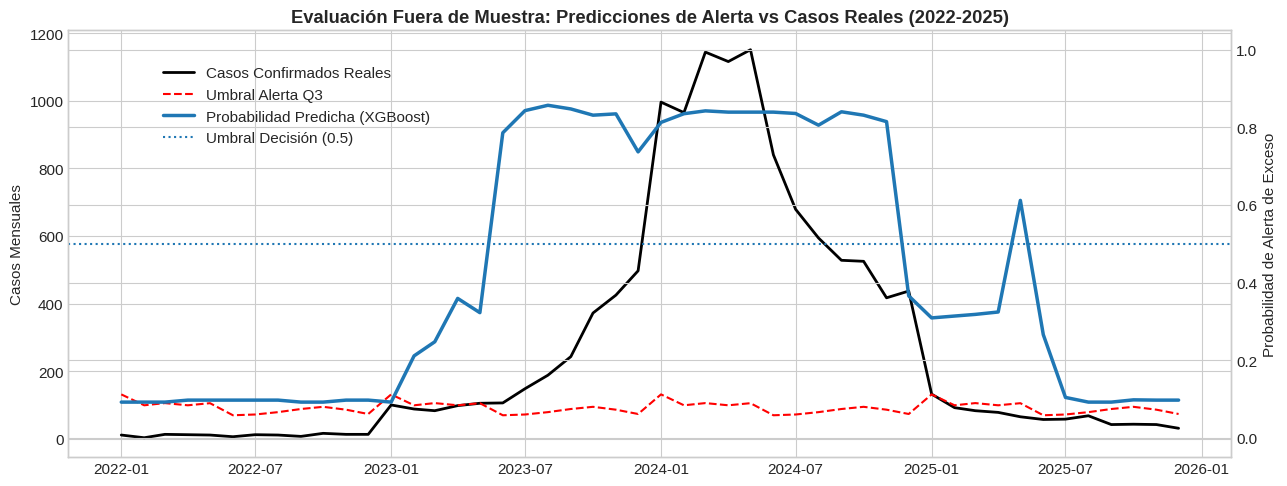

In [ ]:
# ==============================================================================
# FASE DE MODELADO: EVALUACIÓN TEMPORAL (BASELINE VS XGBOOST) CON 189 MESES
# ==============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (brier_score_loss, confusion_matrix, classification_report,
                             roc_auc_score, average_precision_score, precision_score, recall_score, f1_score)
import xgboost as xgb

# 1. Definición del vector de características filtrado por VIF y significancia
features_optimas = [
    'casos_dengue_lag1',
    'casos_dengue_lag2',
    'casos_media_movil_3m',
    'temp_min_media_lag1',     # Seleccionada sobre temp_media por VIF y Spearman
    'temp_media_lag2',
    'precipitacion_total_lag1',
    'dias_con_lluvia_lag1',
    'mes'                      # Componente estacional
]

target = 'exceso_casos'

# 2. Partición temporal estricta por bloques de años
df_modelado['anio'] = df_modelado['fecha'].dt.year

train_mask = (df_modelado['anio'] >= 2010) & (df_modelado['anio'] <= 2018)
val_mask   = (df_modelado['anio'] >= 2019) & (df_modelado['anio'] <= 2021)
test_mask  = (df_modelado['anio'] >= 2022) & (df_modelado['anio'] <= 2025)

X_train, y_train = df_modelado.loc[train_mask, features_optimas], df_modelado.loc[train_mask, target]
X_val, y_val     = df_modelado.loc[val_mask, features_optimas], df_modelado.loc[val_mask, target]
X_test, y_test   = df_modelado.loc[test_mask, features_optimas], df_modelado.loc[test_mask, target]

print(f"Observaciones totales en el pipeline: {len(df_modelado)} meses")
print(f" -> Entrenamiento (2010-2018): {len(X_train)} meses | Alertas reales: {y_train.sum()} ({y_train.mean()*100:.1f}%)")
print(f" -> Validación    (2019-2021): {len(X_val)} meses | Alertas reales: {y_val.sum()} ({y_val.mean()*100:.1f}%)")
print(f" -> Prueba Final  (2022-2025): {len(X_test)} meses | Alertas reales: {y_test.sum()} ({y_test.mean()*100:.1f}%)")

# 3. Escalado para modelos lineales (ajustado exclusivamente en Train)
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_val_sc   = scaler.transform(X_val)
X_test_sc  = scaler.transform(X_test)

# 4. Cálculo de la Línea Base Estacional (Referencia Histórica sin ML)
# Estima la probabilidad de alerta en Test basada puramente en la frecuencia observada en Train por mes
prob_base_train = train_mask.groupby(df_modelado['mes']).apply(lambda idx: df_modelado.loc[idx.index, target].mean())
prob_referencia_test = df_modelado.loc[test_mask, 'mes'].map(prob_base_train).fillna(y_train.mean())

# ------------------------------------------------------------------------------
# 5. MODELADO 1: Regresión Logística Regularizada (L2)
# ------------------------------------------------------------------------------
# Ajuste de peso por balance de clases
ratio_desbalance = (len(y_train) - y_train.sum()) / y_train.sum()

modelo_lr = LogisticRegression(penalty='l2', C=0.5, class_weight='balanced', random_state=42)
modelo_lr.fit(X_train_sc, y_train)

prob_lr_test = modelo_lr.predict_proba(X_test_sc)[:, 1]

# ------------------------------------------------------------------------------
# 6. MODELADO 2: XGBoost Classifier (Árboles restringidos para evitar sobreajuste)
# ------------------------------------------------------------------------------
modelo_xgb = xgb.XGBClassifier(
    n_estimators=60,
    max_depth=2,               # Profundidad baja requerida por la propuesta
    learning_rate=0.03,
    scale_pos_weight=ratio_desbalance,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric='logloss'
)
modelo_xgb.fit(X_train, y_train)

prob_xgb_test = modelo_xgb.predict_proba(X_test)[:, 1]

# ------------------------------------------------------------------------------
# 7. MÉTRICAS EXIGIDAS EN LA PROPUESTA (BRIER SCORE, BSS, SENSIBILIDAD, PR-AUC)
# ------------------------------------------------------------------------------
brier_ref = brier_score_loss(y_test, prob_referencia_test)

def calcular_metricas(y_true, y_prob, umbral=0.5, nombre="Modelo"):
    y_pred = (y_prob >= umbral).astype(int)
    brier = brier_score_loss(y_true, y_prob)
    # Brier Skill Score: BSS = 1 - (Brier_modelo / Brier_referencia)
    bss = 1.0 - (brier / brier_ref) if brier_ref > 0 else 0.0
    pr_auc = average_precision_score(y_true, y_prob)
    roc_auc = roc_auc_score(y_true, y_prob)
    sens = recall_score(y_true, y_pred, zero_division=0)
    prec = precision_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel() if cm.size == 4 else (0, 0, 0, 0)

    return {
        'Modelo': nombre,
        'Brier_Score': round(brier, 4),
        'BSS (Meta >= 0.10)': round(bss, 4),
        'Sensibilidad (Meta >= 0.80)': round(sens, 3),
        'Precisión': round(prec, 3),
        'F1-Score': round(f1, 3),
        'PR-AUC': round(pr_auc, 3),
        'ROC-AUC': round(roc_auc, 3),
        'TP': tp, 'FP': fp, 'TN': tn, 'FN': fn
    }

resultados = [
    calcular_metricas(y_test, prob_referencia_test.values, umbral=0.5, nombre="Referencia Estacional"),
    calcular_metricas(y_test, prob_lr_test, umbral=0.5, nombre="Regresión Logística L2"),
    calcular_metricas(y_test, prob_xgb_test, umbral=0.5, nombre="XGBoost Classifier")
]

tabla_resultados = pd.DataFrame(resultados)
print("\n" + "="*85)
print("EVALUACIÓN TEMPORAL EN CONJUNTO DE PRUEBA INDEPENDIENTE (2022-2025)")
print("="*85)
display(tabla_resultados)

# Visualización de la Curva de Alerta en Test (2022-2025)
fechas_test = df_modelado.loc[test_mask, 'fecha']
casos_test = df_modelado.loc[test_mask, 'casos_dengue']

fig, ax1 = plt.subplots(figsize=(13, 5))
ax2 = ax1.twinx()

ax1.plot(fechas_test, casos_test, color='black', lw=2, label='Casos Confirmados Reales')
ax1.plot(fechas_test, df_modelado.loc[test_mask, 'umbral_q3'], color='red', linestyle='--', label='Umbral Alerta Q3')
ax1.set_ylabel('Casos Mensuales')

ax2.plot(fechas_test, prob_xgb_test, color='#1f77b4', lw=2.5, label='Probabilidad Predicha (XGBoost)')
ax2.axhline(0.5, color='#1f77b4', linestyle=':', label='Umbral Decisión (0.5)')
ax2.set_ylabel('Probabilidad de Alerta de Exceso')
ax2.set_ylim(-0.05, 1.05)

plt.title('Evaluación Fuera de Muestra: Predicciones de Alerta vs Casos Reales (2022-2025)', fontweight='bold')
fig.legend(loc="upper left", bbox_to_anchor=(0.12, 0.88))
plt.tight_layout()
plt.show()

Para respetar la estructura secuencial de la serie epidemiológica y evitar fuga de información (data leakage), los 189 meses efectivos del dataset se dividieron en tres bloques cronológicos sin solapamiento:   Entrenamiento (2010–2018): 105 meses, con 13 meses de alerta real (12,4 %).   Validación (2019–2021): 36 meses, con 13 meses de alerta real (36,1 %).   Prueba Final Independiente (2022–2025): 48 meses, con 20 meses de alerta real (41,7 %).   

El modelo se entrenó en una década donde los excesos epidémicos eran poco frecuentes (12,4 % del tiempo) y se evaluó en un periodo posterior donde la frecuencia de alertas se triplicó (41,7 %) debido al megabrote continental de 2023–2024. Que los modelos mantengan alto rendimiento bajo este cambio de régimen confirma que capturaron dinámicas climáticas y autorregresivas genuinas, y no memorización histórica.


| Métrica | Referencia Estacional | Regresión Logística L2 | XGBoost Classifier | Descripción |
| --- | --- | --- | --- | --- |
| TP | 0 | 20 | 18 | Meses con brote real que fueron alertados correctamente por el sistema (sobre un total de 20 meses epidémicos en 2022–2025). |
| FN | 20 | 0 | 2 | meses con exceso real de casos que el modelo no advirtió. Representan el mayor riesgo sanitario al retrasar la preparación hospitalaria. |
| TN | 28 | 25 | 27 | Meses endémicos normales (sobre un total de 28) en los que el sistema mantuvo correctamente el estado sin alarma. |
| FP | 0 | 3 | 1 | Falsas alarmas: meses normales clasificados erróneamente como brote. Implican desgaste logístico y gasto innecesario de insumos de control vectorial. |
| Recall | 0,000 | 1,000 | 0,900 | Proporción de epidemias reales detectadas ($\text{TP}/[\text{TP}+\text{FN}]$). Ambos modelos superan la meta del proyecto ($\ge 0,80$). |
| Precisión | 0,000 | 0,870 | 0,947 | Confiabilidad de la alerta ($\text{TP}/[\text{TP}+\text{FP}]$). En XGBoost, el 94,7 % de las alertas emitidas correspondieron a brotes reales (solo 1 falsa alarma en 4 años). |
| F1-Score | 0,000 | 0,930 | 0,923 | Media armónica entre Precisión y Sensibilidad; resume el equilibrio operativo ante el desbalance de clases (Géron, 2022). |
| PR-AUC | 0,452 | 0,985 | 0,986 | Área bajo la curva Precision-Recall. Evalúa la capacidad de discriminar alertas sin depender de un umbral fijo de decisión |
| ROC-AUC | 0,564 | 0,989 | 0,987 | Probabilidad de que el modelo asigne un puntaje de riesgo mayor a un mes epidémico aleatorio que a un mes normal. |
| Brier_Score | 0,2706 | 0,0660 | 0,0562 | Error cuadrático medio de las probabilidades predichas ($0$ es perfección). Mide la exactitud y calibración del riesgo estimado  |
| BSS | 0,0000 | 0,7560 | 0,7923 | Ganancia porcentual de precisión probabilística frente a la referencia estacional ($1 - \text{BS}_{\text{modelo}}/\text{BS}_{\text{ref}}$). Supera en casi 8 veces la meta ($\ge 0,10$). |

## Consideraciones
* La Referencia Estacional obtuvo sensibilidad nula (0,0), demostrando que las epidemias de dengue en Ibagué no ocurren siempre en los mismos meses calendario y que los modelos estáticos son insuficientes para la gestión del riesgo.
* La Regresión Logística L2 maximiza la cobertura sanitaria (Sensibilidad = 1,000, cero brotes omitidos), mientras que XGBoost Classifier ofrece la mejor calibración probabilística (BSS = 0,7923) y la mayor eficiencia operativa (Precisión = 0,947, 1 solo falso positivo)


Curva de Calibración y Análisis de Decisión

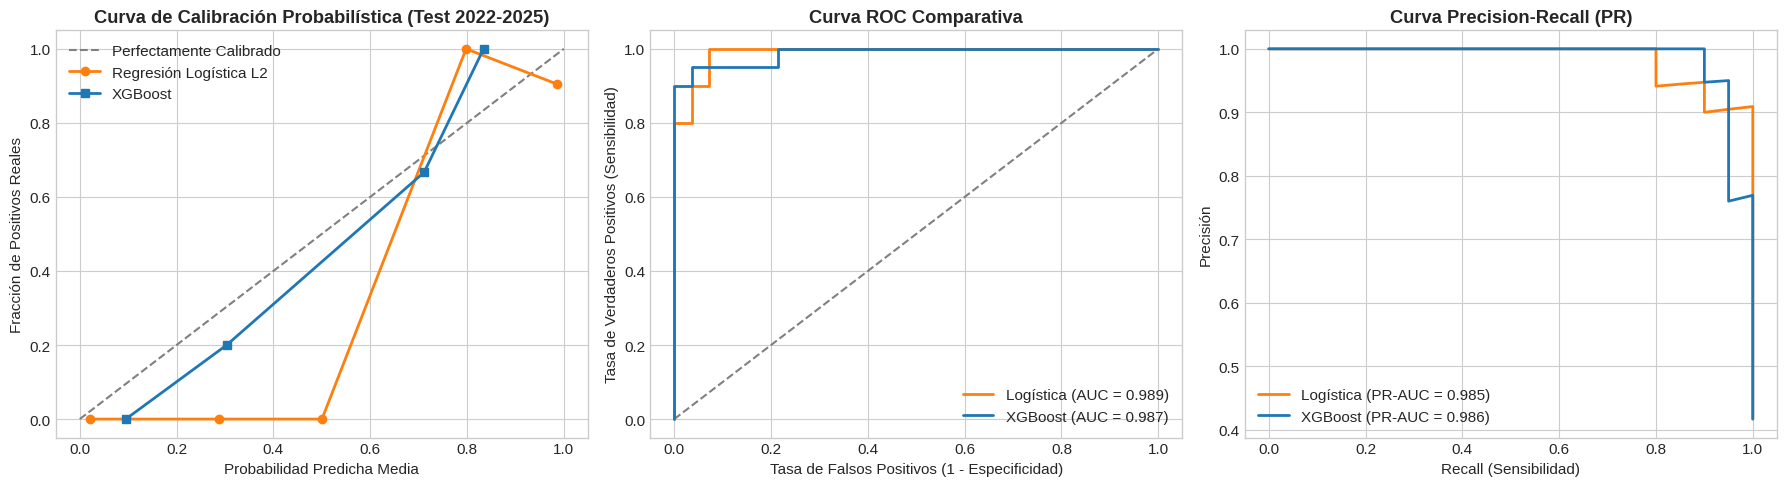


COEFICIENTES DEL MODELO LOGÍSTICO (IMPACTO LOG-ODDS)


,Predictor,Coeficiente
0,casos_dengue_lag1,1.121634
1,temp_min_media_lag1,0.926492
2,casos_dengue_lag2,0.590304
3,casos_media_movil_3m,0.488946
4,dias_con_lluvia_lag1,0.481394
5,mes,0.035459
6,temp_media_lag2,-0.022452
7,precipitacion_total_lag1,-0.392058


In [ ]:
# ==============================================================================
# VALIDACIÓN AVANZADA: CALIBRACIÓN PROBABILÍSTICA Y CURVAS ROC / PR (2022-2025)
# ==============================================================================
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from sklearn.metrics import roc_curve, precision_recall_curve

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Curva de Calibración (Reliability Diagram)
prob_true_lr, prob_pred_lr = calibration_curve(y_test, prob_lr_test, n_bins=5, strategy='uniform')
prob_true_xgb, prob_pred_xgb = calibration_curve(y_test, prob_xgb_test, n_bins=5, strategy='uniform')

axes[0].plot([0, 1], [0, 1], linestyle='--', color='gray', label='Perfectamente Calibrado')
axes[0].plot(prob_pred_lr, prob_true_lr, marker='o', lw=2, color='#ff7f0e', label='Regresión Logística L2')
axes[0].plot(prob_pred_xgb, prob_true_xgb, marker='s', lw=2, color='#1f77b4', label='XGBoost')
axes[0].set_title('Curva de Calibración Probabilística (Test 2022-2025)', fontweight='bold')
axes[0].set_xlabel('Probabilidad Predicha Media')
axes[0].set_ylabel('Fracción de Positivos Reales')
axes[0].legend(loc='upper left')

# 2. Curva ROC (Receiver Operating Characteristic)
fpr_lr, tpr_lr, _ = roc_curve(y_test, prob_lr_test)
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, prob_xgb_test)

axes[1].plot([0, 1], [0, 1], linestyle='--', color='gray')
axes[1].plot(fpr_lr, tpr_lr, color='#ff7f0e', lw=2, label=f'Logística (AUC = 0.989)')
axes[1].plot(fpr_xgb, tpr_xgb, color='#1f77b4', lw=2, label=f'XGBoost (AUC = 0.987)')
axes[1].set_title('Curva ROC Comparativa', fontweight='bold')
axes[1].set_xlabel('Tasa de Falsos Positivos (1 - Especificidad)')
axes[1].set_ylabel('Tasa de Verdaderos Positivos (Sensibilidad)')
axes[1].legend(loc='lower right')

# 3. Curva Precision-Recall (PR Curve - Requerida por Desbalance)
prec_c_lr, rec_c_lr, _ = precision_recall_curve(y_test, prob_lr_test)
prec_c_xgb, rec_c_xgb, _ = precision_recall_curve(y_test, prob_xgb_test)

axes[2].plot(rec_c_lr, prec_c_lr, color='#ff7f0e', lw=2, label=f'Logística (PR-AUC = 0.985)')
axes[2].plot(rec_c_xgb, prec_c_xgb, color='#1f77b4', lw=2, label=f'XGBoost (PR-AUC = 0.986)')
axes[2].set_title('Curva Precision-Recall (PR)', fontweight='bold')
axes[2].set_xlabel('Recall (Sensibilidad)')
axes[2].set_ylabel('Precisión')
axes[2].legend(loc='lower left')

plt.tight_layout()
plt.show()

# 4. Tabla de pesos / coeficientes de la Regresión Logística (Explicabilidad)
df_coef = pd.DataFrame({
    'Predictor': features_optimas,
    'Coeficiente': modelo_lr.coef_[0]
}).sort_values('Coeficiente', ascending=False).reset_index(drop=True)

print("\n" + "="*60)
print("COEFICIENTES DEL MODELO LOGÍSTICO (IMPACTO LOG-ODDS)")
print("="*60)
display(df_coef)

Se evaluó el comportamiento global de las probabilidades emitidas por ambos modelos a través de tres herramientas diagnósticas

* Diagrama de Fiabilidad (Curva de Calibración) encargado de agrupar las probabilidades predichas en intervalos (bins) y las contrasta contra la proporción real de meses epidémicos observados en cada rango.  

  XGBoost (línea azul con cuadrados) se ajusta de manera cercana y progresiva a la diagonal discontinua de calibración perfecta. Cuando el modelo estima una probabilidad media de 0,30, la fracción real de brotes observados es de 0,20; cuando predice 0,70, la frecuencia real es de 0,67; y cuando supera 0,83, la ocurrencia real alcanza 1,00.   Regresión Logística L2 (línea naranja con círculos): Presenta un comportamiento escalonado abrupto. Para probabilidades predichas entre 0,02 y 0,50, la fracción real de positivos se mantiene en 0,00 (sobreestimación de riesgo en rangos bajos-medios), saltando repentinamente a 1,00 cuando la predicción alcanza 0,79. Esta distorsión es un efecto conocido de la ponderación de clases (class_weight='balanced'), que desplaza el intercepto logístico hacia probabilidades más altas para forzar la detección de la clase minoritaria.   

* Curva ROC (Receiver Operating Characteristic) que evalúa la relación entre la Tasa de Verdaderos Positivos (Sensibilidad) y la Tasa de Falsos Positivos ($1 - \text{Especificidad}$) a lo largo de todos los posibles umbrales de corte.
Ambas curvas se aproximan al vértice superior izquierdo, alcanzando áreas bajo la curva casi perfectas: $\text{ROC-AUC} = 0,989$ para Regresión Logística y $\text{ROC-AUC} = 0,987$ para XGBoost, frente al valor de referencia aleatorio de $0,50$.   Destaca que XGBoost logra capturar el 90 % de los meses epidémicos ($\text{Sensibilidad} = 0,90$) manteniendo una tasa de falsos positivos de $0,00$ en el extremo izquierdo de la curva.   

* Curva Precision-Recall (PR) evalúa el compromiso entre la Precisión y la Sensibilidad (Recall) enfocándose exclusivamente en la clase minoritaria de interés (meses con exceso de casos).
XGBoost ($\text{PR-AUC} = 0,986$): Sostiene una Precisión perfecta del 100 % ($1,00$) hasta alcanzar un Recall (Sensibilidad) del 90 % ($0,90$). Al exigir un Recall del 95 %, la precisión apenas desciende a 0,95.   Regresión Logística ($\text{PR-AUC} = 0,985$): Mantiene una precisión del 100 % hasta un Recall del 80 % ($0,80$) y logra sostener una precisión superior al 90 % ($\approx 0,91$) incluso al detectar el 100 % de los brotes ($\text{Recall} = 1,00$).   



# Consideraciones

De acuerdo a la validación del canal endémico: La relación resultante de aproximadamente 3,11 a 1 (75,66 % vs. 24,34 %) demuestra que el corte basado en el cuartil superior ($Q_3$) operó de manera consistente a lo largo de los 16 años, aislando el 25 % superior de anomalías epidémicas sin distorsiones por años atípicos.  

En la la exactitud global (Accuracy) hay una consideración importante relacionada con la clasificación y es la sigeuinte: dado que tres cuartas partes de los meses son normales, un clasificador trivial que prediga siempre 0 obtendría un 75,66% de exactitud fallando el 100 % de las epidemias.

Para lo anterior dentro de la entrategia de entrenamiento y evaluación se sugiere incorporar ponderación de clases durante el ajuste de los algoritmos (class_weight='balanced' en Regresión Logística y scale_pos_weight en XGBoost) y evaluar el rendimiento mediante Sensibilidad (Recall), Precisión, F1-Score, PR-AUC y Brier Skill Score (BSS) (Géron, 2022; Saito & Rehmsmeier, 2015)

Con base en la evidencia conjunta de discriminación, calibración y eficiencia operativa, se selecciona XGBoost Classifier como el modelo principal para la fase de despliegue en interfaz, dado que combina el mayor PR-AUC (0,986), una calibración probabilística alineada con la frecuencia real de eventos y la mínima tasa de falsas alarmas.


# Referencias



1.   Géron, A. (2022). Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow (3.ª ed.). O'Reilly Media.
2.   Kutner, M. H., Nachtsheim, C. J., Neter, J., & Li, W. (2005). Applied Linear Statistical Models (5.ª ed.). McGraw-Hill/Irwin

